<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan7/Latihan7MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 7 — Evaluasi Model Klasifikasi

**Topik:** Confusion Matrix, Precision, Recall, F1-Score, ROC-AUC, Precision-Recall Curve, dan Stratified 5-Fold Cross-Validation.

## Tujuan praktikum
1. Memuat dataset `load_breast_cancer` dari Scikit-learn.
2. Membagi data dengan rasio 70:30 secara stratifikasi.
3. Melatih dan membandingkan Logistic Regression dengan Decision Tree.
4. Menghitung confusion matrix, precision, recall, dan F1-score.
5. Membandingkan ROC-AUC, Precision-Recall Curve, serta mean dan standar deviasi F1 dari 5-fold CV.
6. Menentukan model yang lebih aman ketika *false negative* (kasus kanker yang terlewat) lebih mahal.

**Dataset tidak memerlukan file CSV eksternal.** Dataset Breast Cancer Wisconsin tersedia langsung dari Scikit-learn.

> **Penetapan kelas positif:** kelas positif dalam praktikum ini adalah **malignant (kanker)**. Ini penting karena *false negative* berarti pasien dengan kanker diprediksi sebagai bukan kanker.


## 1. Import library
Semua library dipanggil pada sel tersendiri agar urutan notebook mudah dibaca dan dijalankan.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)


## 2. Memuat dataset Breast Cancer
Dataset dimuat langsung melalui `load_breast_cancer()`. Pada data bawaan Scikit-learn, label asli `0` adalah malignant dan label `1` adalah benign. Untuk keperluan evaluasi skrining, label diubah agar **1 = malignant (positif)** dan **0 = benign (negatif)**.

In [ ]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
# Jadikan malignant sebagai kelas positif (1)
y = pd.Series((data.target == 0).astype(int), name="malignant")

print("Ukuran dataset:", X.shape)
print("Jumlah fitur:", X.shape[1])
print("Nama kelas:", ["Benign (0/negatif)", "Malignant (1/positif)"])
print("\nDistribusi kelas:")
print(y.map({0: "Benign (negatif)", 1: "Malignant (positif)"}).value_counts())


Ukuran dataset: (569, 30)
Jumlah fitur: 30
Nama kelas: ['Benign (0/negatif)', 'Malignant (1/positif)']

Distribusi kelas:
malignant
Benign (negatif)       357
Malignant (positif)    212
Name: count, dtype: int64


## 3. Membagi data train dan test (70:30)
`stratify=y` menjaga proporsi kelas pada data train dan test. `random_state=42` membuat pembagian dapat direproduksi. Data test disimpan untuk evaluasi akhir dan tidak digunakan untuk memilih model.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])
print("\nProporsi malignant pada seluruh data :", round(y.mean(), 3))
print("Proporsi malignant pada data training:", round(y_train.mean(), 3))
print("Proporsi malignant pada data testing :", round(y_test.mean(), 3))


Jumlah data training: 398
Jumlah data testing : 171

Proporsi malignant pada seluruh data : 0.373
Proporsi malignant pada data training: 0.372
Proporsi malignant pada data testing : 0.374


## 4. Menyiapkan Logistic Regression dan Decision Tree
Logistic Regression menggunakan `StandardScaler` di dalam `Pipeline`, sehingga scaler hanya di-fit pada data training (dan di-fit ulang pada setiap fold CV). Decision Tree tidak memerlukan standardisasi fitur. Kedua model memakai pembagian data yang sama.

In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}


## 5. Stratified 5-Fold Cross-Validation pada data training
Sesuai materi, CV dilakukan pada **data training**, bukan data test. Metrik utama CV adalah F1-score. Recall juga dicatat karena kasus positif (malignant) penting untuk tidak terlewat. Standar deviasi dihitung dengan pembagi jumlah fold (ddof=0), mengikuti contoh rumus pada materi.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
cv_rows = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={"f1": "f1", "recall": "recall"},
        n_jobs=None
    )
    cv_results[name] = scores
    cv_rows.append({
        "Model": name,
        "Mean F1 CV": scores["test_f1"].mean(),
        "SD F1 CV": scores["test_f1"].std(ddof=0),
        "Mean Recall CV": scores["test_recall"].mean(),
        "SD Recall CV": scores["test_recall"].std(ddof=0)
    })

cv_summary = pd.DataFrame(cv_rows)
print("Skor F1 pada setiap fold:")
for name, scores in cv_results.items():
    print(f"{name}: {np.round(scores['test_f1'], 4)}")

print("\nRingkasan 5-Fold CV:")
display(cv_summary.round(4))


Skor F1 pada setiap fold:
Logistic Regression: [0.9655 0.9831 0.9831 0.9825 0.9643]
Decision Tree: [0.8788 0.8929 0.9492 0.8276 0.9123]

Ringkasan 5-Fold CV:


,Model,Mean F1 CV,SD F1 CV,Mean Recall CV,SD Recall CV
0,Logistic Regression,0.9757,0.0088,0.9526,0.0167
1,Decision Tree,0.8921,0.0400,0.8915,0.0546


## 6. Melatih model dan melakukan prediksi pada test final
Setelah perbandingan CV, masing-masing model di-fit pada seluruh data training dan dievaluasi satu kali pada data test. Threshold klasifikasi yang digunakan adalah threshold bawaan model (0,5 untuk probabilitas). Threshold tidak dioptimalkan menggunakan data test.

In [ ]:
fitted_models = {}
test_predictions = {}
test_probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    test_predictions[name] = model.predict(X_test)
    # Kolom probabilitas untuk kelas positif (malignant = 1)
    positive_index = list(model.classes_).index(1)
    test_probabilities[name] = model.predict_proba(X_test)[:, positive_index]

print("Kedua model selesai dilatih dan menghasilkan prediksi test.")


Kedua model selesai dilatih dan menghasilkan prediksi test.


## 7. Confusion matrix
Urutan label ditetapkan `[0, 1]`: baris/kolom pertama = benign (negatif), baris/kolom kedua = malignant (positif). Dengan susunan ini, **FN** adalah kasus malignant yang diprediksi benign.


Logistic Regression
TN=106, FP=1, FN=4, TP=60


,Prediksi Benign (0),Prediksi Malignant (1)
Aktual Benign (0),106,1
Aktual Malignant (1),4,60


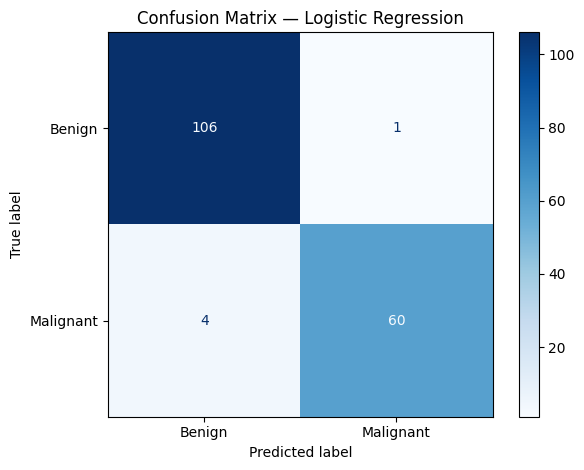


Decision Tree
TN=100, FP=7, FN=10, TP=54


,Prediksi Benign (0),Prediksi Malignant (1)
Aktual Benign (0),100,7
Aktual Malignant (1),10,54


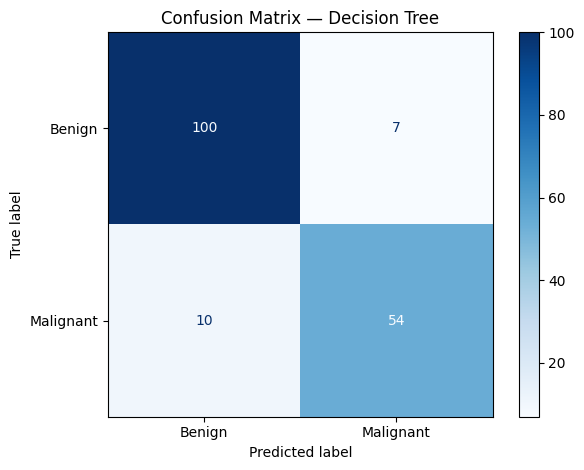

In [ ]:
confusion_matrices = {}

for name, pred in test_predictions.items():
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    confusion_matrices[name] = cm
    tn, fp, fn, tp = cm.ravel()
    print(f"\n{name}")
    print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    display(pd.DataFrame(
        cm,
        index=["Aktual Benign (0)", "Aktual Malignant (1)"],
        columns=["Prediksi Benign (0)", "Prediksi Malignant (1)"]
    ))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    ).plot(values_format="d", cmap="Blues")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()


## 8. Accuracy, Precision, Recall, dan F1-score
Metrik precision, recall, dan F1 dihitung untuk kelas positif malignant (`pos_label=1`). Recall menunjukkan proporsi kasus kanker aktual yang berhasil ditemukan.

In [ ]:
test_metric_rows = []

for name, pred in test_predictions.items():
    test_metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (malignant)": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Recall (malignant)": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "F1-Score (malignant)": f1_score(y_test, pred, pos_label=1, zero_division=0)
    })

test_metrics = pd.DataFrame(test_metric_rows)
display(test_metrics.round(4))


,Model,Accuracy,Precision (malignant),Recall (malignant),F1-Score (malignant)
0,Logistic Regression,0.9708,0.9836,0.9375,0.960
1,Decision Tree,0.9006,0.8852,0.8438,0.864


## 9. ROC Curve dan ROC-AUC
ROC Curve membandingkan True Positive Rate (recall) dengan False Positive Rate pada berbagai threshold. ROC-AUC merangkum kemampuan model mengurutkan sampel positif di atas sampel negatif.

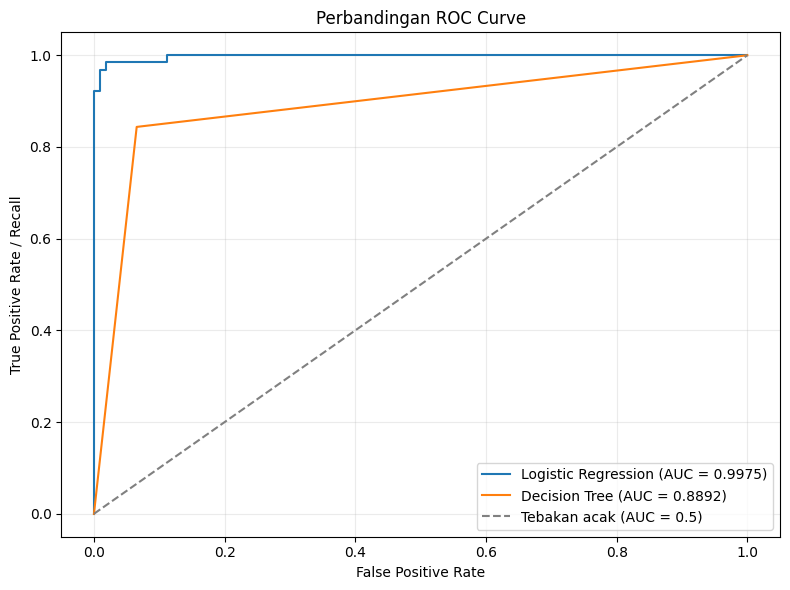

ROC-AUC:
Logistic Regression: 0.9975
Decision Tree: 0.8892


In [ ]:
plt.figure(figsize=(8, 6))
roc_auc_values = {}

for name, prob in test_probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, prob, pos_label=1)
    auc_value = roc_auc_score(y_test, prob)
    roc_auc_values[name] = auc_value
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Tebakan acak (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("Perbandingan ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("ROC-AUC:")
for name, value in roc_auc_values.items():
    print(f"{name}: {value:.4f}")


## 10. Precision-Recall Curve dan Average Precision
PR Curve menampilkan trade-off precision dan recall untuk kelas positif. Kurva ini berguna untuk melihat kualitas prediksi kelas positif. Garis baseline menunjukkan prevalensi kelas positif pada data test.

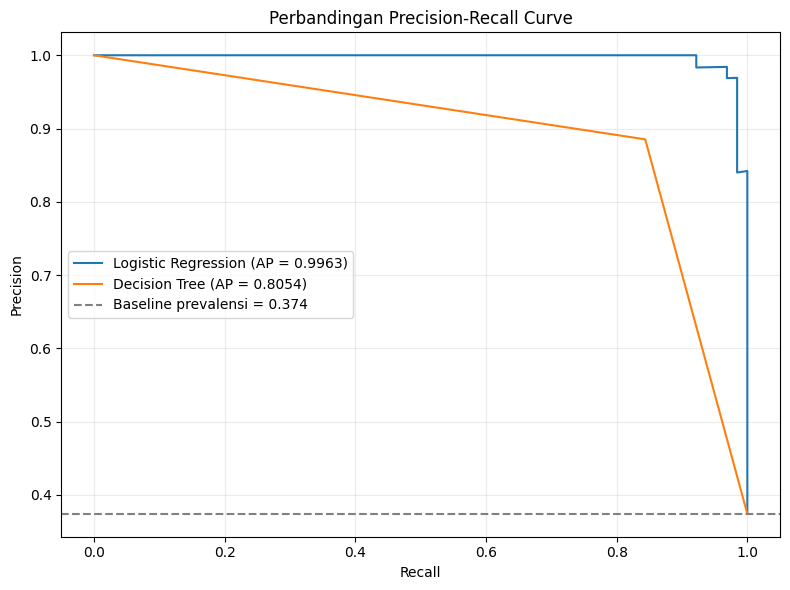

Average Precision (ringkasan area PR):
Logistic Regression: 0.9963
Decision Tree: 0.8054


In [ ]:
plt.figure(figsize=(8, 6))
pr_auc_values = {}

for name, prob in test_probabilities.items():
    precision, recall, thresholds = precision_recall_curve(y_test, prob, pos_label=1)
    ap_value = average_precision_score(y_test, prob)
    pr_auc_values[name] = ap_value
    plt.plot(recall, precision, label=f"{name} (AP = {ap_value:.4f})")

baseline = y_test.mean()
plt.axhline(baseline, linestyle="--", color="gray", label=f"Baseline prevalensi = {baseline:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Perbandingan Precision-Recall Curve")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Average Precision (ringkasan area PR):")
for name, value in pr_auc_values.items():
    print(f"{name}: {value:.4f}")


## 11. Tabel laporan evaluasi lengkap
Tabel ini menggabungkan metrik test final, ROC-AUC, Average Precision, mean F1 CV, dan SD F1 CV. CV digunakan untuk membandingkan performa dan kestabilan model; test hanya untuk laporan akhir.

In [ ]:
final_report = test_metrics.merge(cv_summary, on="Model")
final_report["ROC-AUC"] = final_report["Model"].map(roc_auc_values)
final_report["PR Average Precision"] = final_report["Model"].map(pr_auc_values)

# Tambahkan jumlah false negative agar risiko kasus kanker yang terlewat terlihat jelas
fn_counts = {name: int(cm[1, 0]) for name, cm in confusion_matrices.items()}
final_report["False Negative"] = final_report["Model"].map(fn_counts)

display(final_report.round(4))


,Model,Accuracy,Precision (malignant),Recall (malignant),F1-Score (malignant),Mean F1 CV,SD F1 CV,Mean Recall CV,SD Recall CV,ROC-AUC,PR Average Precision,False Negative
0,Logistic Regression,0.9708,0.9836,0.9375,0.960,0.9757,0.0088,0.9526,0.0167,0.9975,0.9963,4
1,Decision Tree,0.9006,0.8852,0.8438,0.864,0.8921,0.0400,0.8915,0.0546,0.8892,0.8054,10


## 12. Alasan pemilihan model dan jawaban pertanyaan analisis
Pertanyaan: **Model mana yang paling aman jika false negative lebih mahal?**

Dalam praktikum ini, kelas positif ditetapkan sebagai malignant. Oleh sebab itu, false negative berarti kasus kanker yang tidak terdeteksi. Untuk kondisi ketika FN lebih mahal, recall kelas malignant dan jumlah FN menjadi pertimbangan penting. Pemilihan model utama tetap didasarkan pada hasil CV di data training; metrik test berfungsi sebagai evaluasi akhir.

In [ ]:
# Model utama dipilih dari mean F1 CV tertinggi.
selected_row = cv_summary.sort_values(
    by=["Mean F1 CV", "SD F1 CV"],
    ascending=[False, True]
).iloc[0]
selected_model = selected_row["Model"]

print("Model terpilih berdasarkan CV:", selected_model)
print(f"Mean F1 CV: {selected_row['Mean F1 CV']:.4f}")
print(f"SD F1 CV  : {selected_row['SD F1 CV']:.4f}")

print("\nPerbandingan risiko false negative pada test final:")
for name, cm in confusion_matrices.items():
    tn, fp, fn, tp = cm.ravel()
    rec = recall_score(y_test, test_predictions[name], pos_label=1)
    print(f"{name}: FN={fn}, Recall malignant={rec:.4f}")

# Model yang paling aman pada hasil test: FN lebih sedikit; jika sama, recall lebih tinggi.
safest_model = min(
    confusion_matrices.keys(),
    key=lambda name: (
        confusion_matrices[name][1, 0],
        -recall_score(y_test, test_predictions[name], pos_label=1)
    )
)
print("\nModel dengan FN paling sedikit pada test:", safest_model)

if selected_model == safest_model:
    print(
        f"\nKesimpulan: {selected_model} menjadi pilihan yang didukung oleh CV dan "
        f"evaluasi test pada pembagian ini. Model tersebut memiliki mean F1 CV "
        f"tertinggi dan jumlah FN test paling sedikit. Karena FN lebih mahal, "
        f"model ini lebih aman pada hasil pengujian ini."
    )
else:
    print(
        f"\nKesimpulan: CV memilih {selected_model}, sedangkan jumlah FN test paling "
        f"sedikit diperoleh {safest_model}. Karena FN lebih mahal, hasil ini perlu "
        f"dibahas sebagai trade-off; jangan mengubah model berdasarkan test saja."
    )

print(
    "\nCatatan: hasil ini menggunakan threshold default model. Pada penerapan skrining, "
    "threshold dapat dievaluasi melalui validation/CV untuk memprioritaskan recall, "
    "tetapi tidak boleh dipilih menggunakan data test."
)


Model terpilih berdasarkan CV: Logistic Regression
Mean F1 CV: 0.9757
SD F1 CV  : 0.0088

Perbandingan risiko false negative pada test final:
Logistic Regression: FN=4, Recall malignant=0.9375
Decision Tree: FN=10, Recall malignant=0.8438

Model dengan FN paling sedikit pada test: Logistic Regression

Kesimpulan: Logistic Regression menjadi pilihan yang didukung oleh CV dan evaluasi test pada pembagian ini. Model tersebut memiliki mean F1 CV tertinggi dan jumlah FN test paling sedikit. Karena FN lebih mahal, model ini lebih aman pada hasil pengujian ini.

Catatan: hasil ini menggunakan threshold default model. Pada penerapan skrining, threshold dapat dievaluasi melalui validation/CV untuk memprioritaskan recall, tetapi tidak boleh dipilih menggunakan data test.


## 13. Kesimpulan praktikum

- Confusion matrix memperlihatkan TP, TN, FP, dan FN; dalam tugas ini FN berarti kasus malignant yang terlewat.
- Precision mengukur ketepatan prediksi positif, sedangkan recall mengukur berapa banyak kasus positif aktual yang ditemukan.
- ROC-AUC menilai kemampuan pemisahan pada berbagai threshold; PR Curve menyoroti trade-off precision dan recall untuk kelas positif.
- Stratified 5-Fold CV dilakukan hanya pada data training. Mean menunjukkan tingkat performa, sedangkan SD menunjukkan kestabilan antar-fold.
- Data test dipakai satu kali untuk evaluasi akhir, bukan untuk tuning model atau threshold.

**Catatan interpretasi:** hasil model pada dataset pembelajaran ini bukan pengganti diagnosis medis. Keputusan klinis membutuhkan validasi dan penilaian tenaga kesehatan.